In [1]:
import pandas as pd 
import numpy as np
from pathlib import Path 
from datetime import datetime
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
pd.set_option('display.max_columns', 100)

In [2]:
data_path = Path("data") / "raw" / "creditcard.csv"
print(data_path)

data\raw\creditcard.csv


In [3]:
df = pd.read_csv(f"../{data_path}")

## EDA

In [4]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [6]:
summary = pd.DataFrame({
    'dtype': df.dtypes,
    'non-null': df.notna().sum(),
    'null_%': (df.isna().mean() * 100).round(2),
    'unique': df.nunique(),
})
summary

,dtype,non-null,null_%,unique
Time,float64,284807,0.0,124592
V1,float64,284807,0.0,275663
V2,float64,284807,0.0,275663
V3,float64,284807,0.0,275663
V4,float64,284807,0.0,275663
V5,float64,284807,0.0,275663
V6,float64,284807,0.0,275663
V7,float64,284807,0.0,275663
V8,float64,284807,0.0,275663
V9,float64,284807,0.0,275663


In [7]:
print("Missing values total:", df.isna().sum().sum())
print("Duplicate rows       :", df.duplicated().sum())
print("Constant columns     :", [c for c in df.columns if df[c].nunique() <= 1])

Missing values total: 0
Duplicate rows       : 1081
Constant columns     : []


In [8]:
# Look at the duplicates
dups = df[df.duplicated(keep=False)]
print("Rows involved in duplicates:", len(dups))
print("Fraud rows among duplicates:", dups['Class'].sum())

Rows involved in duplicates: 1854
Fraud rows among duplicates: 32


In [9]:
df.shape

(284807, 31)

In [10]:
df['Class'].value_counts() # classes are imbalanced

Class
0    284315
1       492
Name: count, dtype: int64

Counts:
 Class
0    284315
1       492
Name: count, dtype: int64

Percent:
 Class
0    99.827
1     0.173
Name: proportion, dtype: float64


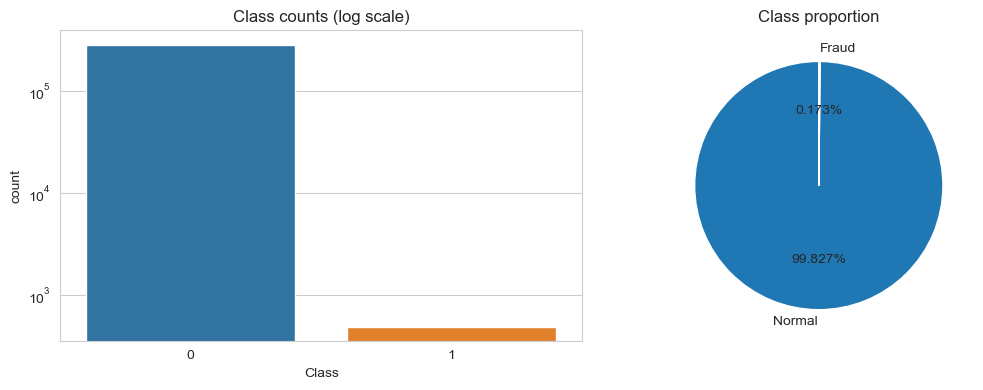

In [11]:
counts = df['Class'].value_counts()
rate = df['Class'].value_counts(normalize=True) * 100

print("Counts:\n", counts)
print("\nPercent:\n", rate.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x='Class', data=df, ax=ax[0])
ax[0].set_title("Class counts (log scale)")
ax[0].set_yscale('log')

ax[1].pie(counts, labels=['Normal','Fraud'], autopct='%1.3f%%', startangle=90)
ax[1].set_title("Class proportion")
plt.tight_layout()
plt.show()

## Dealing with Time

In [12]:
print("Time min/max (sec):", df["Time"].min(), df["Time"].max())
print("Span in hours:", (df["Time"].max() - df["Time"].min()) / 3600)
print("Span in days :", (df["Time"].max() - df["Time"].min()) / 86400)

Time min/max (sec): 0.0 172792.0
Span in hours: 47.99777777777778
Span in days : 1.9999074074074075


In [13]:
df["hour"] = (df["Time"] % 86400) // 3600          
df["hour_float"] = (df["Time"] % 86400) / 3600     
df["day"] = df["Time"] // 86400                    

In [14]:
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

In [15]:
bins   = [-1, 5, 11, 17, 23]
labels = ["night", "morning", "afternoon", "evening"]
df["part_of_day"] = pd.cut(df["hour"], bins=bins, labels=labels)

df[["Time", "hour", "hour_float", "day", "hour_sin", "hour_cos", "part_of_day"]].head()

,Time,hour,hour_float,day,hour_sin,hour_cos,part_of_day
0,0.0,0.0,0.000000,0.0,0.0,1.0,night
1,0.0,0.0,0.000000,0.0,0.0,1.0,night
2,1.0,0.0,0.000278,0.0,0.0,1.0,night
3,1.0,0.0,0.000278,0.0,0.0,1.0,night
4,2.0,0.0,0.000556,0.0,0.0,1.0,night


## Dealing with amount

In [16]:
print(df['Amount'].describe())
print("\nZero-amount transactions", (df['Amount'] == 0).sum())
print('Skewness', df['Amount'].skew())

count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64

Zero-amount transactions 1825
Skewness 16.977724453761024


In [17]:
# Fraud hour by hour
hourly = df.groupby('hour').agg(
    n_txns = ("Class", "size"), # no. of transactions 
    n_fraud = ('Class', "sum")
)
hourly['fraud_rate'] = hourly['n_fraud'] / hourly['n_txns']
hourly

,n_txns,n_fraud,fraud_rate
hour,,,
0.0,7695,6,0.000780
1.0,4220,10,0.002370
2.0,3328,57,0.017127
3.0,3492,17,0.004868
4.0,2209,23,0.010412
5.0,2990,11,0.003679
6.0,4101,9,0.002195
7.0,7243,23,0.003175
8.0,10276,9,0.000876


In [18]:
hourly = df.groupby('hour').agg(
    n_txns=('Class','size'),
    n_fraud=('Class','sum')
)
hourly['fraud_rate'] = hourly['n_fraud'] / hourly['n_txns']
hourly

,n_txns,n_fraud,fraud_rate
hour,,,
0.0,7695,6,0.000780
1.0,4220,10,0.002370
2.0,3328,57,0.017127
3.0,3492,17,0.004868
4.0,2209,23,0.010412
5.0,2990,11,0.003679
6.0,4101,9,0.002195
7.0,7243,23,0.003175
8.0,10276,9,0.000876


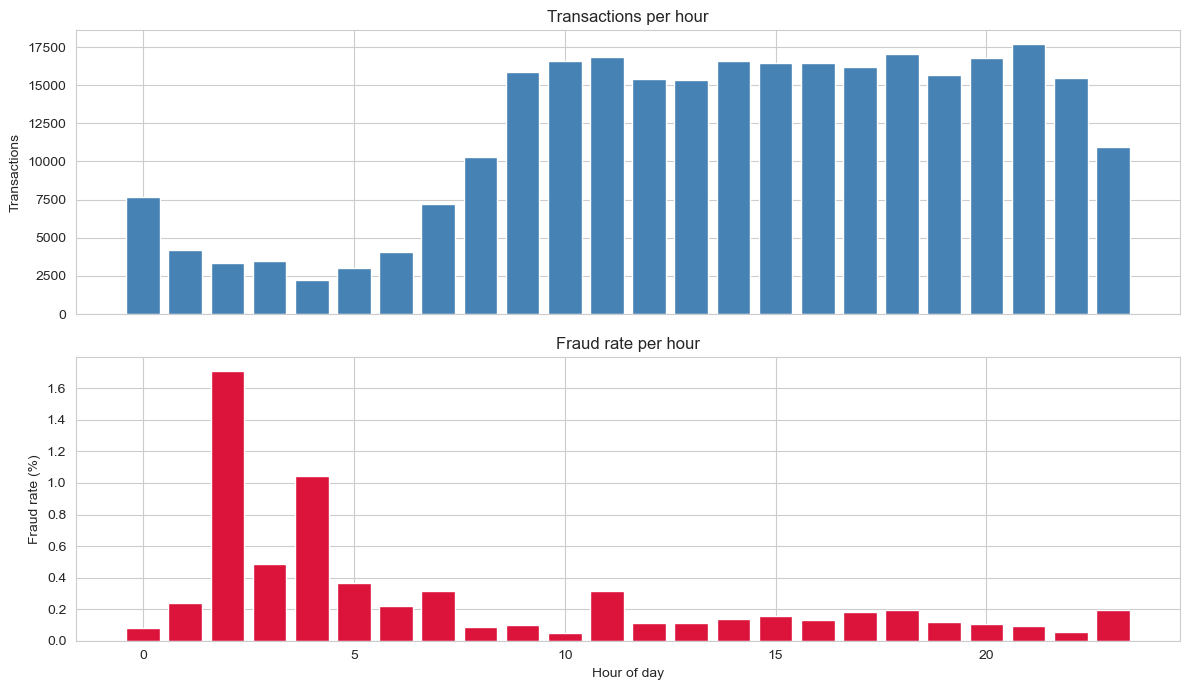

In [19]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

ax[0].bar(hourly.index, hourly['n_txns'], color='steelblue')
ax[0].set_ylabel("Transactions")
ax[0].set_title("Transactions per hour")

ax[1].bar(hourly.index, hourly['fraud_rate'] * 100, color='crimson')
ax[1].set_ylabel("Fraud rate (%)")
ax[1].set_xlabel("Hour of day")
ax[1].set_title("Fraud rate per hour")

plt.tight_layout()
plt.show()

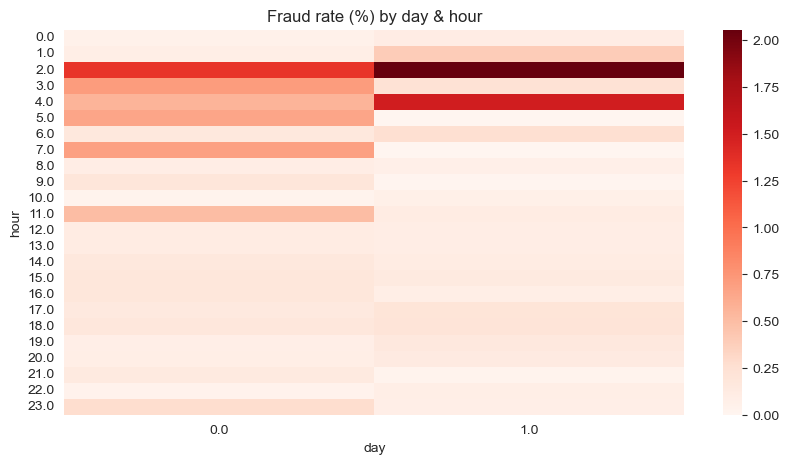

In [20]:
# Day x Hour fraud rate heatmap
pivot = df.pivot_table(values='Class', index='hour', columns='day', aggfunc='mean') * 100
sns.heatmap(pivot, cmap='Reds', annot=False)
plt.title("Fraud rate (%) by day & hour")
plt.show()